In [1]:
import numpy as np
import pandas as pd

In [2]:
# till now
# Timestamp
pd.Timestamp('25 June 2026 10:15')

# DatetimeIndex
pd.DatetimeIndex([pd.Timestamp('25 June 2026 10:15'),pd.Timestamp('26 June 2026 10:15'),
                  pd.Timestamp('27 June 2026 10:15')]) # it a collection of timestamp
# we can retrive timestamp using indexing 

# date_range()
pd.date_range(start='2026-6-1',end='2026-6-30',freq='D')

# to_datetime()

s = pd.Series(['2026/6/1','2026/6/2','2026/6/3']) 
pd.to_datetime(s) # use to convert date of string datatype to datetime datatype so we can perform and retirve operations on date

0   2026-06-01
1   2026-06-02
2   2026-06-03
dtype: datetime64[us]

Timedelta Object

Represents a duration, the difference between two dates or times.

In [3]:
# create using Timestamp objects
t1 = pd.Timestamp('23 June 2026 00:00:00')
t2 = pd.Timestamp('25 June 2026 10:33:00')

t2 - t1

Timedelta('2 days 10:33:00')

In [4]:
# standalone creation
pd.Timedelta(days=2,hours=5,minutes=34,seconds=44)

Timedelta('2 days 05:34:44')

In [5]:
# Arithmetic
pd.Timestamp('23 June 2026 00:00:00') + pd.Timedelta(days=2,hours=5,minutes=34,seconds=44)

Timestamp('2026-06-25 05:34:44')

In [6]:
pd.date_range(start='2026-6-1',end='2026-6-30',freq='D') - pd.Timedelta(days=2,hours=5,minutes=34,seconds=44)

DatetimeIndex(['2026-05-29 18:25:16', '2026-05-30 18:25:16',
               '2026-05-31 18:25:16', '2026-06-01 18:25:16',
               '2026-06-02 18:25:16', '2026-06-03 18:25:16',
               '2026-06-04 18:25:16', '2026-06-05 18:25:16',
               '2026-06-06 18:25:16', '2026-06-07 18:25:16',
               '2026-06-08 18:25:16', '2026-06-09 18:25:16',
               '2026-06-10 18:25:16', '2026-06-11 18:25:16',
               '2026-06-12 18:25:16', '2026-06-13 18:25:16',
               '2026-06-14 18:25:16', '2026-06-15 18:25:16',
               '2026-06-16 18:25:16', '2026-06-17 18:25:16',
               '2026-06-18 18:25:16', '2026-06-19 18:25:16',
               '2026-06-20 18:25:16', '2026-06-21 18:25:16',
               '2026-06-22 18:25:16', '2026-06-23 18:25:16',
               '2026-06-24 18:25:16', '2026-06-25 18:25:16',
               '2026-06-26 18:25:16', '2026-06-27 18:25:16'],
              dtype='datetime64[us]', freq='D')

In [7]:
# real life example
df = pd.read_csv('dataset_files\session-22\deliveries.csv')
df.head()

<>:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\himan\AppData\Local\Temp\ipykernel_13228\2366635468.py:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  df = pd.read_csv('dataset_files\session-22\deliveries.csv')


,order_date,delivery_date
0,5/24/98,2/5/99
1,4/22/92,3/6/98
2,2/10/91,8/26/92
3,7/21/92,11/20/97
4,9/2/93,6/10/98


In [8]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['delivery_date'] = pd.to_datetime(df['delivery_date'])

C:\Users\himan\AppData\Local\Temp\ipykernel_13228\3472121163.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['order_date'] = pd.to_datetime(df['order_date'])
C:\Users\himan\AppData\Local\Temp\ipykernel_13228\3472121163.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['delivery_date'] = pd.to_datetime(df['delivery_date'])


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_date     501 non-null    datetime64[us]
 1   delivery_date  501 non-null    datetime64[us]
dtypes: datetime64[us](2)
memory usage: 8.0 KB


In [10]:
df['delivery_time_period'] = df['delivery_date'] - df['order_date']

In [11]:
df

,order_date,delivery_date,delivery_time_period
0,1998-05-24,1999-02-05,257 days
1,1992-04-22,1998-03-06,2144 days
2,1991-02-10,1992-08-26,563 days
3,1992-07-21,1997-11-20,1948 days
4,1993-09-02,1998-06-10,1742 days
...,...,...,...
496,1991-06-24,1996-02-02,1684 days
497,1991-09-09,1998-03-30,2394 days
498,1990-11-16,1998-04-27,2719 days
499,1993-06-03,1993-06-13,10 days


In [12]:
df['delivery_time_period'].mean()

Timedelta('1217 days 22:53:53.532934')

# Time series

A time series is a data set that tracks a sample over time. In particular, a time series allows one to see what factors influence certain variables
from period to period. Time series analysis can be useful to see how a given asset, security, or economic variable changes over time.

Examples

- Financial Data (Companx stocks)
- Natural Data (Rainfall measurement)
- Event Data (Covid)
- Medical Data (Heart rate monitoring)

Types of Operations done on Time Series

- Time Series Analysis
- Time Series Forecasting

In [13]:
google = pd.read_csv('dataset_files\session-22\google.csv')

<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\himan\AppData\Local\Temp\ipykernel_13228\1896380556.py:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  google = pd.read_csv('dataset_files\session-22\google.csv')


In [14]:
google.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361
1,2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874
2,2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897
3,2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808
4,2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276


In [16]:
google['Date'] = pd.to_datetime(google['Date'])

In [17]:
google.info()

<class 'pandas.DataFrame'>
RangeIndex: 4471 entries, 0 to 4470
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       4471 non-null   datetime64[us]
 1   Open       4471 non-null   float64       
 2   High       4471 non-null   float64       
 3   Low        4471 non-null   float64       
 4   Close      4471 non-null   float64       
 5   Adj Close  4471 non-null   float64       
 6   Volume     4471 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 244.6 KB


In [18]:
google.set_index('Date',inplace=True)

In [19]:
google.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361
2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874
2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897
2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808
2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276


In [21]:
# fetch a specific date

google.loc['2004-12-31']

Open         9.924301e+01
High         9.956679e+01
Low          9.592046e+01
Close        9.603503e+01
Adj Close    9.603503e+01
Volume       1.539449e+07
Name: 2004-12-31 00:00:00, dtype: float64

In [30]:
# create year month_name and day_name
google['month_name'] = google.index.month_name()
google['weekday_name'] = google.index.day_name()
google['quarter'] = google.index.quarter

In [31]:
google.head()

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361,August,Thursday,3
2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874,August,Friday,3
2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897,August,Monday,3
2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808,August,Tuesday,3
2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276,August,Wednesday,3


In [35]:
# slicing

google.loc['2007-06-1' : '2007-06-23']

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2007-06-01,249.564575,251.567062,248.035309,249.265686,249.265686,9633976,June,Friday,2
2007-06-04,248.025345,254.301819,247.865936,252.588242,252.588242,14255233,June,Monday,2
2007-06-05,253.923233,258.530975,252.359100,258.451263,258.451263,20972517,June,Tuesday,2
2007-06-06,257.410156,259.417633,256.667938,258.157349,258.157349,15832523,June,Wednesday,2
2007-06-07,258.904572,262.266968,255.298080,256.568329,256.568329,21340691,June,Thursday,2
2007-06-08,257.136200,258.849762,253.778778,256.782501,256.782501,12764064,June,Friday,2
2007-06-11,256.050262,258.157349,254.047760,254.715271,254.715271,9330241,June,Monday,2
2007-06-12,253.405182,254.879654,250.645523,251.442535,251.442535,12887124,June,Tuesday,2
2007-06-13,252.598206,253.320496,248.413879,251.676651,251.676651,14120730,June,Wednesday,2


In [40]:
# challenge -> fetch info for a particular date every year -> limitation of timedelta

google[google.index.isin(pd.date_range(start='2005-1-6',end='2022-1-6', freq=pd.DateOffset(years=1)))]

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2005-01-06,97.175758,97.584229,93.509506,93.922951,93.922951,20852067,January,Thursday,1
2006-01-06,227.581970,234.371521,225.773743,231.960556,231.960556,35646914,January,Friday,1
2009-01-06,165.868286,169.763687,162.585587,166.406265,166.406265,12898566,January,Tuesday,1
2010-01-06,311.761444,311.761444,302.047852,302.994293,302.994293,7987226,January,Wednesday,1
2011-01-06,304.199799,308.060303,303.885956,305.604523,305.604523,4131026,January,Thursday,1
2012-01-06,328.344299,328.767700,323.681763,323.796326,323.796326,5405987,January,Friday,1
2014-01-06,554.426880,557.340942,551.154114,556.573853,556.573853,3551864,January,Monday,1
2015-01-06,513.589966,514.761719,499.678131,500.585632,500.585632,2899940,January,Tuesday,1
2016-01-06,730.000000,747.179993,728.919983,743.619995,743.619995,1947000,January,Wednesday,1


<Axes: xlabel='Date'>

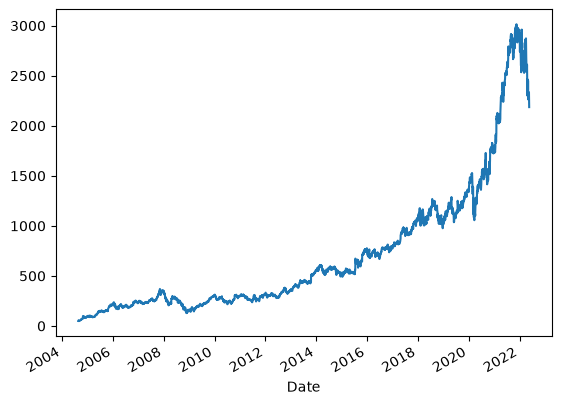

In [41]:
# viz a single col

google['Close'].plot()

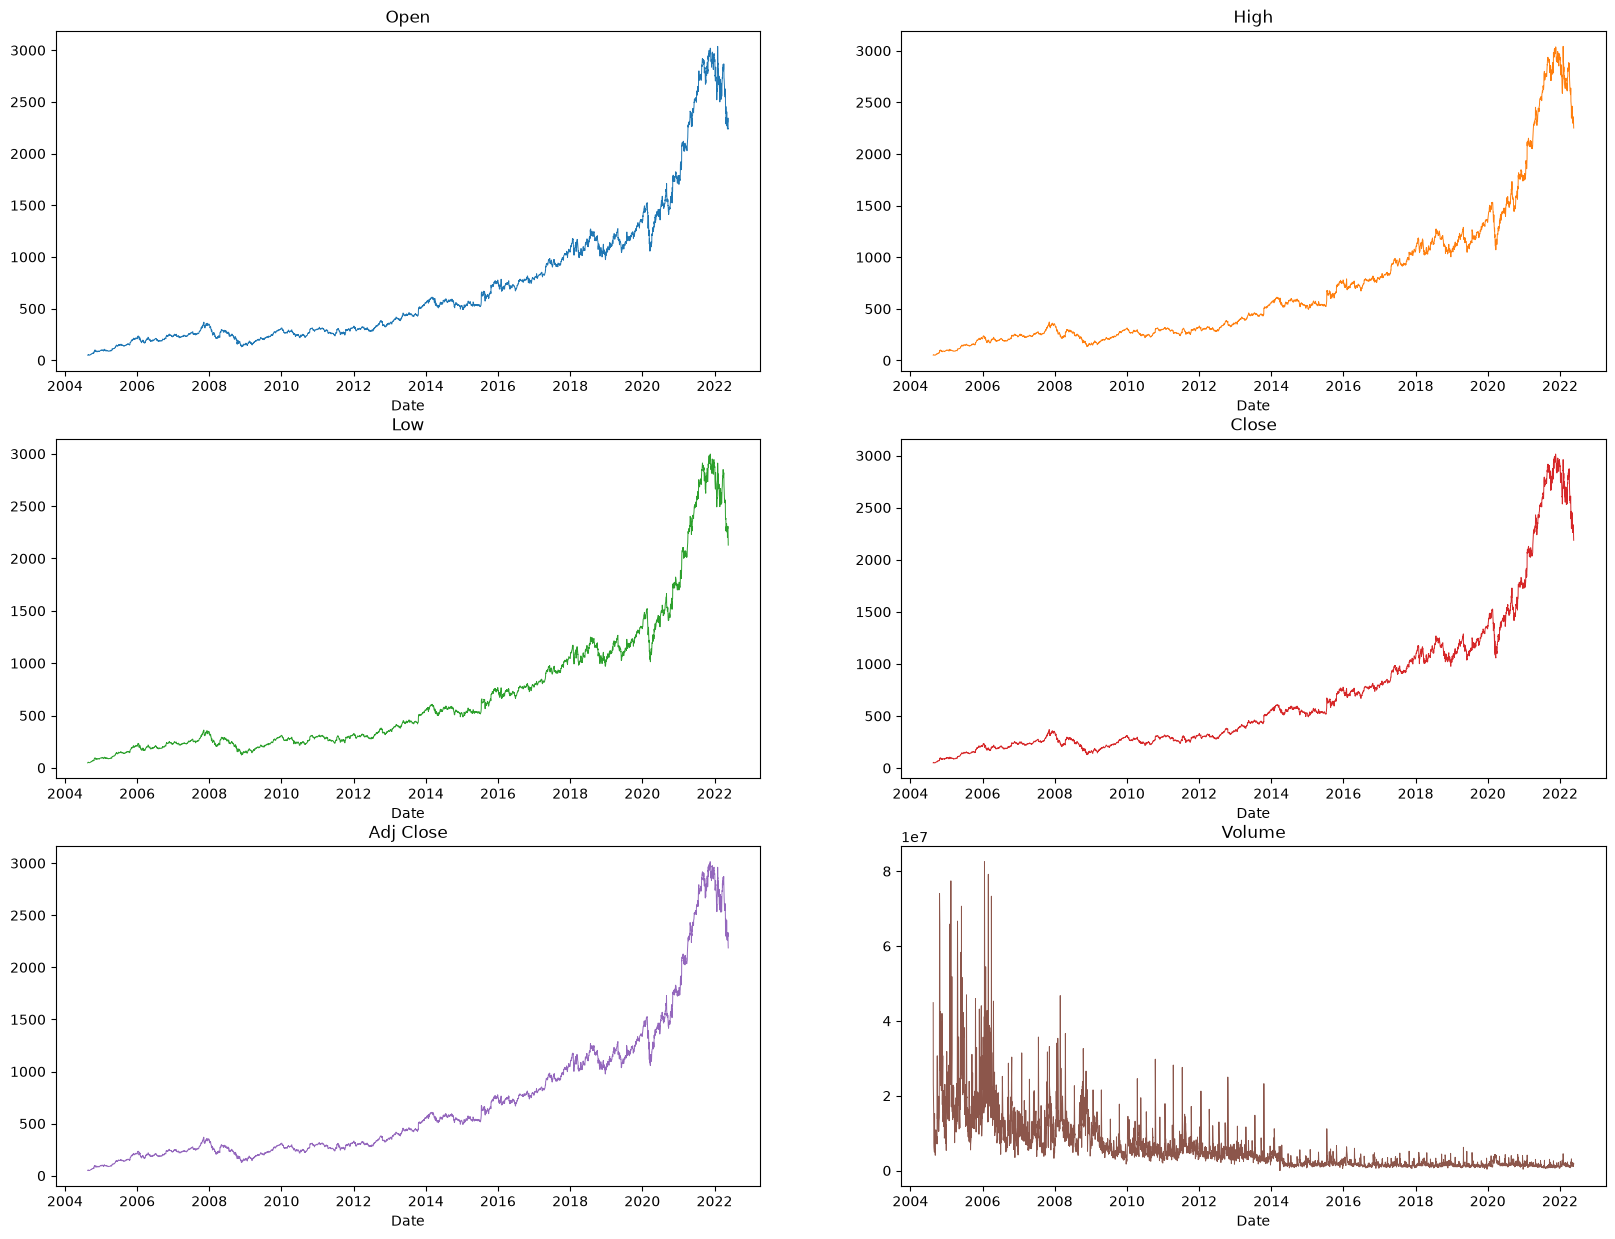

In [51]:
# viz all cols together
subset_google = google[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]
ax = subset_google.plot(subplots=True,
        layout=(3, 2),
        sharex=False,
        sharey=False,
        linewidth=0.7,
        fontsize=10,
        legend=False,
        figsize=(20,15),
        title=['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'])

<Axes: xlabel='Date'>

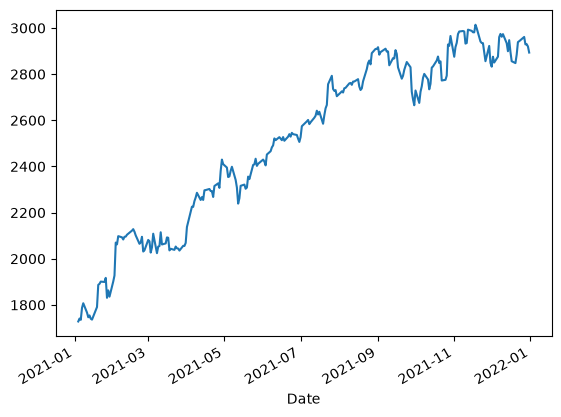

In [53]:
# plot for a particular year/month/week
google.loc['2021']['Close'].plot()

<Axes: xlabel='Date'>

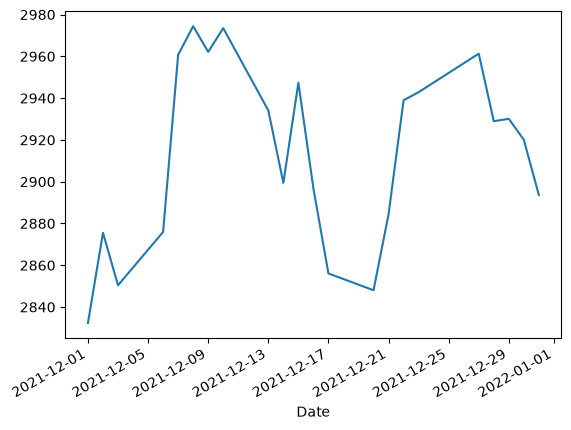

In [ ]:

google.loc['2021-12']['Close'].plot()

<Axes: xlabel='month_name'>

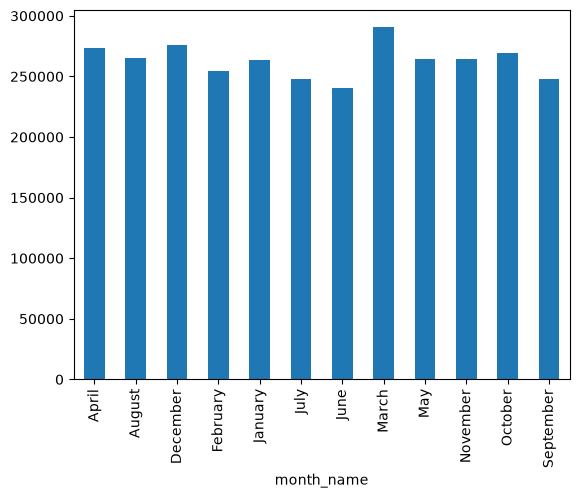

In [58]:
# monthly trend
google.groupby('month_name')['Close'].sum().plot(kind='bar')

<Axes: xlabel='weekday_name'>

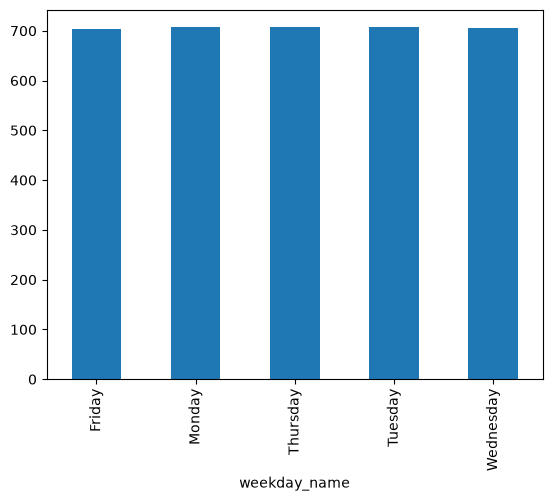

In [59]:
# yearly trend

google.groupby('weekday_name')['Close'].mean().plot(kind='bar')

<Axes: xlabel='quarter'>

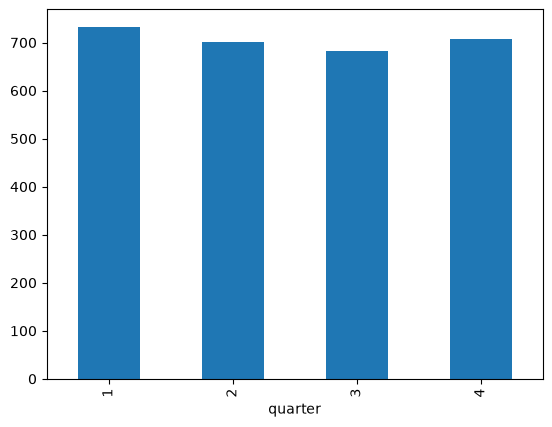

In [60]:
# quaterly trend
google.groupby('quarter')['Close'].mean().plot(kind='bar')

In [ ]:
# frequency

google.index # we can add freq in this as it is none

DatetimeIndex(['2004-08-19', '2004-08-20', '2004-08-23', '2004-08-24',
               '2004-08-25', '2004-08-26', '2004-08-27', '2004-08-30',
               '2004-08-31', '2004-09-01',
               ...
               '2022-05-09', '2022-05-10', '2022-05-11', '2022-05-12',
               '2022-05-13', '2022-05-16', '2022-05-17', '2022-05-18',
               '2022-05-19', '2022-05-20'],
              dtype='datetime64[us]', name='Date', length=4471, freq=None)

In [63]:
# asfreq
google.asfreq('B')

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361.0,August,Thursday,3.0
2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874.0,August,Friday,3.0
2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897.0,August,Monday,3.0
2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808.0,August,Tuesday,3.0
2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276.0,August,Wednesday,3.0
...,...,...,...,...,...,...,...,...,...
2022-05-16,2307.679932,2332.149902,2286.699951,2295.850098,2295.850098,1164100.0,May,Monday,2.0
2022-05-17,2344.550049,2344.550049,2306.750000,2334.030029,2334.030029,1078800.0,May,Tuesday,2.0
2022-05-18,2304.750000,2313.913086,2242.840088,2248.020020,2248.020020,1399100.0,May,Wednesday,2.0


# Resampling

Resampling involves changing the frequency of your time series observations.

Two types of resampling are:

Upsampling: Where you increase the frequency of the samples, such as from minutes to seconds.
Downsampling: Where you decrease the frequency of the samples, such as from days to months.

<Axes: xlabel='Date'>

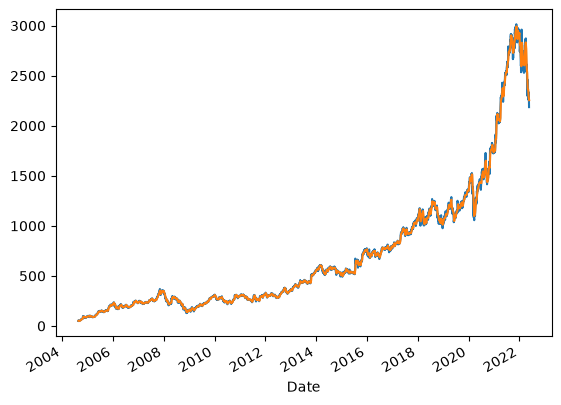

In [69]:
# Downsampling
google['Close'].plot()
google['Close'].resample('W').mean().plot()

In [ ]:
%pip install scipy 

<Axes: xlabel='Date'>

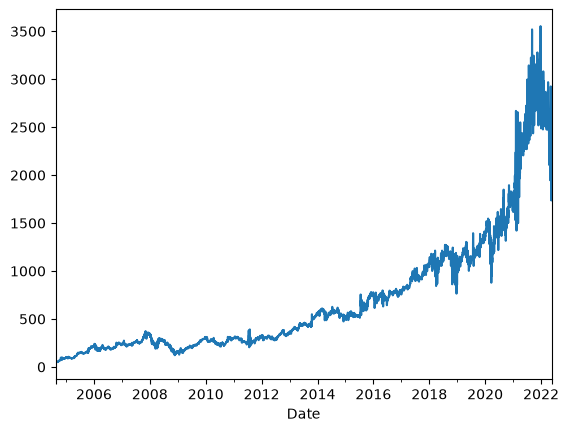

In [74]:
# Upsampling

google['Close'].resample('h').interpolate(method='spline', order=2).plot()

# Rolling Window(Smoothing)

Time series data in original format can be quite volatile, especially on smaller aggregation levels. The concept of rolling, or moving averages is
a useful technique for smoothing time series data.

In [ ]:
# Rolling window

# Shifting

The shift() function is Pandas is used to, well, shift the entire series up or down by the desired number of periods.


In [76]:
# shift
google['Open'].shift(1)

Date
2004-08-19            NaN
2004-08-20      49.813290
2004-08-23      50.316402
2004-08-24      55.168217
2004-08-25      55.412300
                 ...     
2022-05-16    2296.909912
2022-05-17    2307.679932
2022-05-18    2344.550049
2022-05-19    2304.750000
2022-05-20    2236.820068
Name: Open, Length: 4471, dtype: float64

In [77]:
google['Open'].shift(-1)

Date
2004-08-19      50.316402
2004-08-20      55.168217
2004-08-23      55.412300
2004-08-24      52.284027
2004-08-25      52.279045
                 ...     
2022-05-16    2344.550049
2022-05-17    2304.750000
2022-05-18    2236.820068
2022-05-19    2241.709961
2022-05-20            NaN
Name: Open, Length: 4471, dtype: float64

In [82]:
# shift example

login = pd.read_csv('dataset_files\session-22\login.csv',header=None)
login = login[[1,2]]
login.rename(columns={1:'user_id',2:'login_time'},inplace=True)
login.head()

<>:3: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:3: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\himan\AppData\Local\Temp\ipykernel_13228\860360741.py:3: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  login = pd.read_csv('dataset_files\session-22\login.csv',header=None)


,user_id,login_time
0,466,2017-01-07 18:24:07
1,466,2017-01-07 18:24:55
2,458,2017-01-07 18:25:18
3,458,2017-01-07 18:26:21
4,592,2017-01-07 19:09:59


In [84]:
user_df = login[login['user_id'] == 413]
user_df.head()

,user_id,login_time
11,413,2017-01-09 12:29:25
12,413,2017-01-09 12:40:39
14,413,2017-01-09 14:08:04
33,413,2017-01-10 14:36:23
35,413,2017-01-10 15:22:45


In [88]:
user_df['login_time'] = pd.to_datetime(user_df['login_time'])
user_df.info()

<class 'pandas.DataFrame'>
Index: 222 entries, 11 to 2997
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     222 non-null    int64         
 1   login_time  222 non-null    datetime64[us]
 2   shifted     221 non-null    str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 6.9 KB


In [89]:
user_df['shifted' ] = user_df['login_time'].shift(1)
(user_df['login_time'] - user_df['shifted']).mean()

Timedelta('1 days 15:05:13.384615')